In [4]:
import sisl as si
from ase.visualize import view

In [79]:
import matplotlib.pyplot as plt
from matplotlib.colors import to_hex
from IPython.display import Image
import numpy as np
from tqdm.notebook import tqdm
import time
from scipy.spatial import cKDTree
from matplotlib.colors import Normalize

In [6]:
si.__version__

'0.20.0'

In [8]:
from sisl.viz import merge_plots

# Orbital Prunning with `sisl`: a beginner's tutorial

This tutorial introduces the basic ingredients for prunning orbitals in **sisl**. 
The tutorial is divided into two parts:

1. **Nanoporous graphene (NPG): from DFT to a reduced $p_z$ Hamiltonian.** We read a precomputed SIESTA Hamiltonian, inspect its band structure, keep only the carbon and nitrogen $p_z$ orbitals, compare the reduced model with the original DFT bands, visualize selected wave functions, and calculate the transmission along the conducting direction.

2.  **STO**: Systems such as SrTiO$_3$ (STO) exhibit complex band structures, in which the electronic states generally arise from linear combinations of several atomic orbitals. Unlike in graphene or nanoporous graphene (NPG), where a simplified description can be obtained by retaining only the $p_z$ orbitals, the electronic structure of STO cannot be accurately captured using a single orbital type. Instead, the choice of orbitals must be adapted to the bands of interest, whether they belong to the valence band, the conduction band, or another selected subset of bands.
Note that, since we are now considering bulk STO, it is essential to preserve the symmetries of the bulk crystal when selecting the orbital basis. This requires retaining complete sets of symmetry-related orbitals, such as the $p$ orbitals $(p_x,p_y,p_z)$ or the $t_2g$ orbitals $(d_{xy},d_{yz},d_{zx})$.

Tutorial made by Niels Gabriel and Alan Anaya


# I. Nanoporous graphene: reducing a DZP Hamiltonian to a $p_z$ model

## 1. Read the SIESTA Hamiltonian

We begin with a **precomputed DFT Hamiltonian from SIESTA**. `sisl` can read the Hamiltonian directly from the SIESTA input/output files. The resulting object contains both the atomic geometry and the Hamiltonian/overlap matrices needed for the following analysis.

In [9]:
dir = './NPG_DZP' 
# Read Hamiltonian
H_dft = si.get_sile(dir+'/RUN.fdf').read_hamiltonian()

Before doing any electronic-structure or transport calculation, it is useful to inspect the geometry. Here we use `sisl`'s plotting tools to visualize the nanoporous graphene (NPG) structure.

The NPG consists of laterally connected graphene nanoribbons (GNRs). In this example, every second GNR is chemically modified with nitrogen atoms at the bridges.

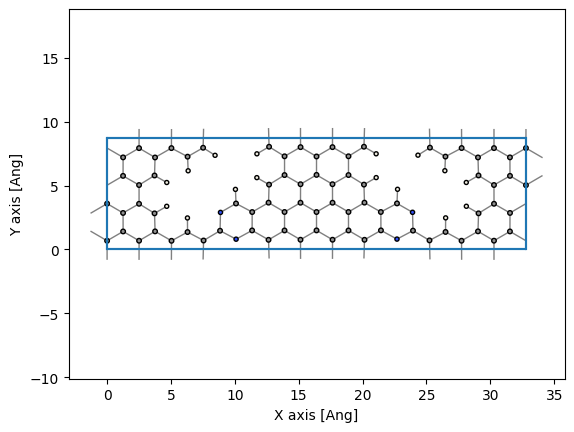

In [10]:
H_dft.geometry.plot(axes='xy',backend='matplotlib')

The same geometry can also be converted to an ASE `Atoms` object and opened with an ASE-compatible viewer. This is useful for interactive inspection of larger structures.

In [11]:
view(H_dft.to.ase())

<Popen: returncode: None args: ['/home/alan/ase_sisl_project/bin/python3', '...>

## 2. Calculate the Band-structure and Fatbands
Next we calculate the **band structure** of the original DFT Hamiltonian. A band-structure calculation requires a path through reciprocal space and a number of $k$ points along that path. Here the path is $X \rightarrow\Gamma
\rightarrow Y$.

In [12]:
nk=30
bs = si.BandStructure(H_dft, [[0.5, 0, 0], [0, 0, 0], [0, 0.5, 0]], nk, [r'$X$', r'$\Gamma$', r'$Y$'])

Next we calculate the **band structure** of the original DFT Hamiltonian. A band-structure calculation requires a path through reciprocal space and a number of $k$ points along that path. Here the path is $X \rightarrow\Gamma\rightarrow Y$


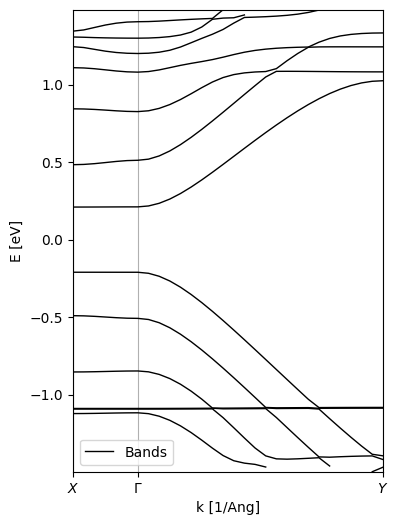

In [13]:
bands=bs.plot.bands( Erange=(-1.5,1.5), backend="matplotlib",)
fig = bands.get().figure
ax = bands.get().axes
fig.set_figwidth(4)
fig.set_figheight(6)
ax.legend()

In [14]:
# Atomic numbers: C = 6, N = 7
Z =H_dft.geometry.atoms.Z
idx = np.arange(H_dft.geometry.na)

We will project the bands into C(z=6) and N(Z=7) atoms in the GNRs

In [15]:
cGNR_atoms = np.where((idx < 50) & np.isin(Z, [6]))[0]
nGNR_atoms = np.where((idx >=50) & np.isin(Z, [6,7]))[0]

We will look at the $2p_zZ1$ projection of the  atoms in those GNRs

In [16]:
groups_dict = { "cGNR": {  "name": "cGNR",  "atoms_idx": cGNR_atoms, "orbitals": ["2pzZ1"], "color": "red", }, 
                "nGNR": {  "name": "nGNR", "atoms_idx": nGNR_atoms,  "orbitals": ["2pzZ1"], "color": "blue",},}

groups = [ {"name": rf"{group['name']} $p_z$","atoms": group["atoms_idx"],  "orbitals": ["2pzZ1"],"color": group["color"], } for group in groups_dict.values()]

In [17]:
# Plot orbital weights on the original band structure
fatbands = bs.plot.fatbands( groups=groups,  Erange=(-2, 2),  E0=0,  fatbands_scale=0.1,  backend="matplotlib",)

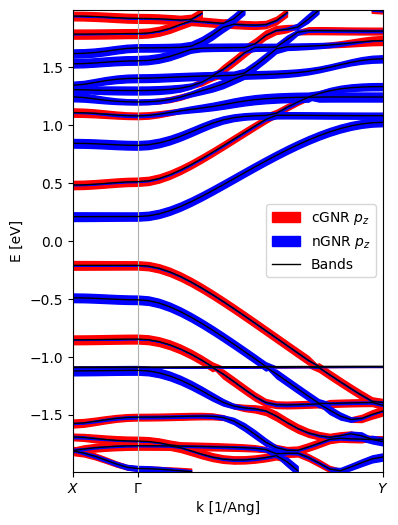

In [18]:
fig = fatbands.get().figure
ax = fatbands.get().axes
fig.set_figwidth(4)
fig.set_figheight(6)
ax.legend()

As you can see the VB and CB have majority contribution from the $p_z$ orbitals 

## 2. Keep only the $p_z$ orbitals

The full DZP basis contains several atomic orbitals per atom. For the low-energy $\pi$ bands of graphene-like systems, the dominant contribution usually comes from the out-of-plane $p_z$ orbitals.

We therefore construct a reduced, tight-binding-like Hamiltonian by keeping only the carbon and nitrogen $p_z$ orbitals.

In [19]:

C_list = (H_dft.atoms.Z == 6).nonzero()[0]
C_atom = H_dft.geometry.atoms[C_list[0]]
Corbs = C_atom.orbitals

# Atoms whose orbitals will be extracted from DFT
C_list = (H_dft.atoms.Z == 6).nonzero()[0]
C_atom = H_dft.geometry.atoms[C_list[0]]
Corbs = C_atom.orbitals

N_list = (H_dft.atoms.Z == 7).nonzero()[0]
N_atom = H_dft.geometry.atoms[N_list[0]]
Norbs  = N_atom.orbitals

print('Nitrogen')
print('orbital number orbtial name')
for i,orb in enumerate(N_atom.orbitals):
    print(i,orb.name())

print('Carbon')
print('orbital number orbtial name')
for i,orb in enumerate(C_atom.orbitals):
    print(i,orb.name())

Nitrogen
orbital number orbtial name
0 2sZ1
1 2sZ2
2 2pyZ1
3 2pzZ1
4 2pxZ1
5 2pyZ2
6 2pzZ2
7 2pxZ2
8 3dxyZ1P
9 3dyzZ1P
10 3dz2Z1P
11 3dxzZ1P
12 3dx2-y2Z1P
Carbon
orbital number orbtial name
0 2sZ1
1 2sZ2
2 2pyZ1
3 2pzZ1
4 2pxZ1
5 2pyZ2
6 2pzZ2
7 2pxZ2
8 3dxyZ1P
9 3dyzZ1P
10 3dz2Z1P
11 3dxzZ1P
12 3dx2-y2Z1P


`sub` can be used to keep a selected subset of atoms, while `sub_orbital` keeps selected orbitals on those atoms.

First we retain only carbon and nitrogen atoms. We then retain orbital index `3`, which was identified above as the relevant $p_z$ orbital for this basis. The result is a much smaller Hamiltonian that is easier to analyze and use in transport calculations.

In [100]:
# List of Carbon and Nitrogen
CN_list = np.array(list(C_list)+list(N_list))
H_tb = H_dft.sub(CN_list)
H_tb.reduce()
H_tb = H_tb.sub_orbital(range(H_tb.geometry.na),[3]) 
H_tb.reduce()

In [101]:
print("Number of atoms:",H_dft.na)
print("Number of orbitals:",H_dft.no)

Number of atoms: 96
Number of orbitals: 1120


In [102]:
print("Number of atoms:",H_tb.na)
print("Number of orbitals:",H_tb.no)

Number of atoms: 80
Number of orbitals: 80


After pruning the basis, the absolute energy reference of the reduced Hamiltonian does not necessarily coincide with that of the original DFT Hamiltonian. We therefore apply a rigid energy shift so that the valence-band edge of the reduced model aligns with the corresponding DFT state.

In [103]:
tmp = H_dft.eigh()
en_dft = tmp[tmp<0].max()
tmp = H_tb.eigh()
en_tb = tmp[tmp<0].max()
print(en_dft, en_tb)

eshift = en_dft - en_tb
H_tb.shift(eshift)
print("Energy shift: ",eshift)

-0.21051013699283047 -0.008584884658254842
Energy shift:  -0.20192525233457562


In [104]:
nk=30
bs_tb = si.BandStructure(H_tb, [[0.5, 0, 0], [0, 0, 0], [0, 0.5, 0]],nk, [r'$X$', r'$\Gamma$', r'$Y$'])

In [105]:
# To get the bands eigenvalues
lk, kt, kl = bs_tb.lineark(True)
bs_tb =bs_tb.apply.array.eigh()
bs_dft =bs.apply.array.eigh()

Text(0, 0.5, '$E-E_F$ (eV)')

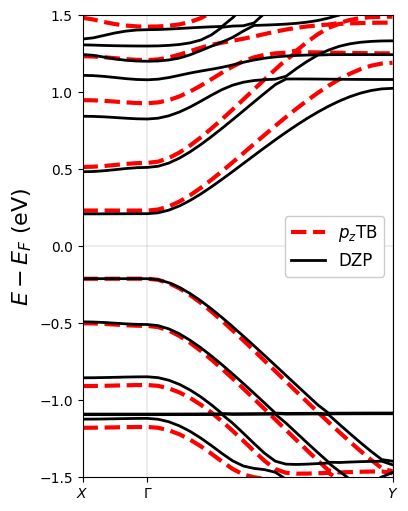

In [106]:
fig = plt.figure('Band comparison',figsize=(4,6))
ax = fig.add_subplot()

firsttime=True
for bk in bs_tb.T:
    bk=bk 
    if(firsttime):
        ax.plot(lk, bk, 'r--', label=r'$p_z$TB',lw=3)
        firsttime=False
    else:
        ax.plot(lk, bk, 'r--',lw=3)
firsttime= True
for bk in bs_dft.T:
    if(firsttime):
        ax.plot(lk, bk, 'k-', label='DZP',lw=2)
        firsttime=False
    else:
        ax.plot(lk, bk, 'k',lw=2)

xcoords = kt
for k in xcoords:
    plt.axvline(x=k,c='k',lw=0.1)  

plt.axhline(y=0,c='k',lw=0.1)  

plt.xticks(kt, kl)        
ax.legend(loc='center right',fontsize=12,framealpha=1)
plt.ylim(-1.5,1.5)
plt.xlim(kt[0],kt[2])
plt.ylabel(r'$E-E_F$ (eV)',fontsize=16)

## 3. Visualize selected electronic states

We now use the reduced $p_z$ Hamiltonian to visualize states close to the valence- and conduction-band edges. `sisl` evaluates the eigenstate wave function on a real-space grid, which allows us to see where the selected state is localized within the NPG unit cell.

Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


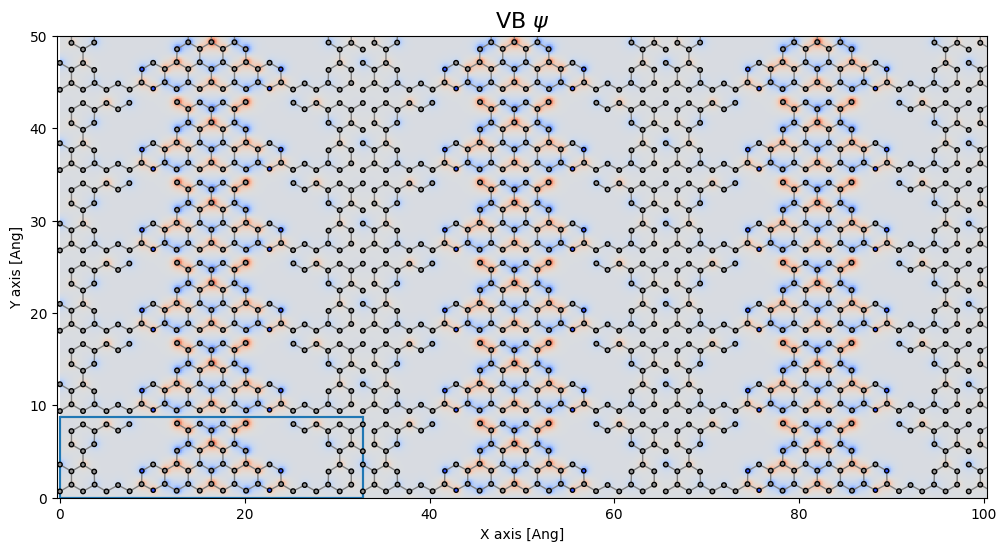

In [37]:
es = H_tb.eigenstate(dtype=np.float64).sub([len(H_tb) // 2 ]) # we pick the VB STATE
grid_spacing = 0.2
g = si.Grid(grid_spacing, dtype=np.float64, geometry=H_tb.geometry)
es.wavefunction(g)

index = g.index([0, 0, 25]) # 0, 0, 25 Å
g_sub = g.sub(index, 2) # z plane

fig = g_sub.plot(axes='xy',plot_geom=True,nsc=[15,10,1],colorscale="coolwarm",backend='matplotlib')
ax = fig.get().axes
ax.set_title(r'VB $\psi$',fontsize=16)
ax.set_xlim(0, 100)
ax.set_ylim(0, 50)
fig.get().set_size_inches(12,6)

Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


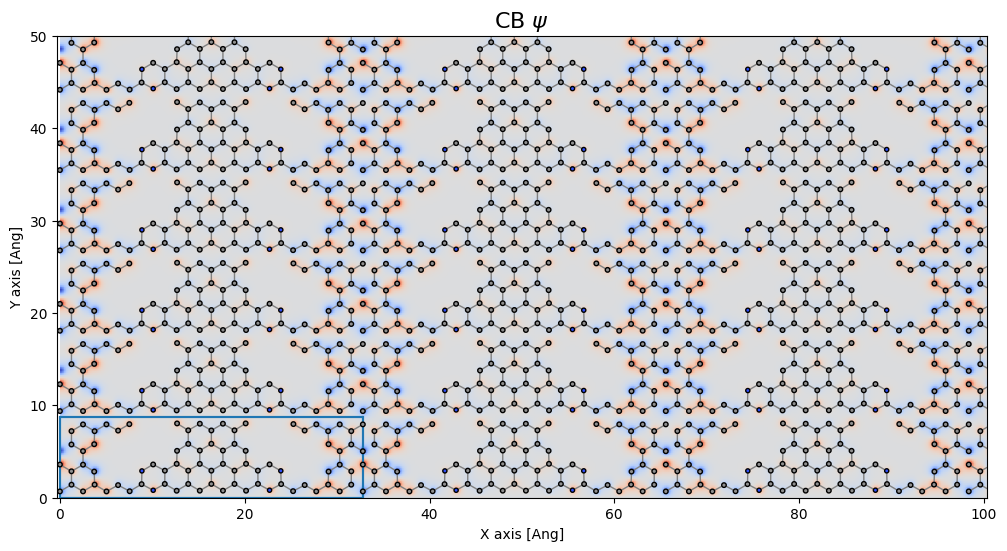

In [38]:
es = H_tb.eigenstate(dtype=np.float64).sub([len(H_tb) // 2 +1])
grid_spacing = 0.2
g = si.Grid(grid_spacing, dtype=np.float64, geometry=H_tb.geometry)
es.wavefunction(g)

index = g.index([0, 0, 25]) # 0, 0, 25 Å
g_sub = g.sub(index, 2) # z plane

fig = g_sub.plot(axes='xy',plot_geom=True,nsc=[15,10,1],colorscale="coolwarm",backend='matplotlib')
ax = fig.get().axes
ax.set_title(r'CB $\psi$',fontsize=16)
ax.set_xlim(0, 100)
ax.set_ylim(0, 50)
fig.get().set_size_inches(12,6)

## 4. Transmission along the NPG

In this exercise, we calculate the transport along the **$y$ direction**, corresponding here to lattice vector `B` (axis `1` in `sisl`). The NPG unit cell is repeated three times along this direction to form a finite device containing a left, central, and right cell.


### Partitioning of the Hamiltonian and the Caroli formula

In quantum transport calculations, we describe an electronic device as a finite central scattering region connected to two semi-infinite electrodes. The electrodes act as electron reservoirs, allowing electrons to enter and leave the device.

$$
\boldsymbol H =
\begin{pmatrix}
\boldsymbol H_L & \boldsymbol V_{LC} & \boldsymbol 0 \\
\boldsymbol V_{CL} & \boldsymbol H_D & \boldsymbol V_{CR} \\
\boldsymbol 0 & \boldsymbol V_{RC} & \boldsymbol H_R
\end{pmatrix}.
$$

Here, $\boldsymbol H_L$ and $ \boldsymbol H_R$ describe the semi-infinite electrodes, $H_C$ describes the finite device, and $ \boldsymbol V_{\alpha\beta}$ describes the coupling between different regions.

![title](./Figures/Device.webp)

For coherent two-terminal transport, the energy- and $k$-resolved transmission is calculated with the Caroli expression

$$T(E,k)=\mathrm{Tr}\left[\boldsymbol\Gamma_L\,\mathbf G^r\,\boldsymbol\Gamma_R\,\mathbf G^a\right],$$

where $\mathbf G^a=(\mathbf G^r)^\dagger$ and

$$\boldsymbol\Gamma_\alpha=i\left(\boldsymbol\Sigma_\alpha-\boldsymbol\Sigma_\alpha^\dagger\right)$$

describes the broadening produced by electrode $\alpha$. The retarded Green function of the open device is

$$\mathbf G^r(E,k)=\left[(E+i\eta)\mathbf S_k-\mathbf H_k-\boldsymbol\Sigma_L(E,k)-\boldsymbol\Sigma_R(E,k)\right]^{-1}.$$

Here $\mathbf H_k$ and $\mathbf S_k$ are the Hamiltonian and overlap matrices at the transverse $k$ point, and $\eta>0$ is a small numerical broadening.

Because the transport direction is now treated as an open direction connected to semi-infinite electrodes, periodicity along $y$ is removed from the finite device by setting the number of supercells in that direction to one.

In [39]:
#Repeat
H_device=H_tb.tile(3,1)
#nx ny nz
H_device.set_nsc([3, 1, 1])

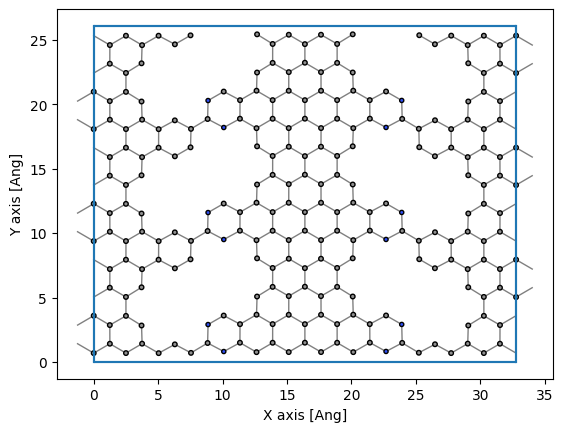

In [40]:
H_device.geometry.plot(axes="xy",backend='matplotlib')

### Recursive method for calculating the self energies

We calculate transport along the **$y$ direction**, corresponding here to lattice vector `B` (axis `1` in `sisl`). The NPG unit cell is repeated three times along this direction to form a finite device containing a left, central, and right cell.

Because the transport direction is now treated as an open direction connected to semi-infinite electrodes, periodicity along $y$ is removed from the finite device by setting the number of supercells in that direction to one.

For a semi-infinite electrode with nearest-neighbor cell coupling, the Hamiltonian has the form

$$
\boldsymbol H_L =
\begin{pmatrix}
\ddots & \ddots & 0 & 0 \\
\ddots &\boldsymbol  H_0 & \boldsymbol V^\dagger & 0 \\
0 & \boldsymbol V & \boldsymbol H_0 &\boldsymbol  V^\dagger \\
0 & 0 & \boldsymbol V & \boldsymbol H_0
\end{pmatrix},
$$

where $\boldsymbol H_0$ is the Hamiltonian of the cell and $\boldsymbol V$ describes the coupling between adjacent cells.

Rather than directly inverting an infinite-dimensional Hamiltonian, we calculate the **surface Green function** using a recursive technique.  

For a detailed discussion of the recursive method, see
M. P. López Sancho, J. M. López Sancho, and J. Rubio. Journal of Physics F: Metal Physics 15, 851 (1985).

For an orthogonal tight-binding Hamiltonian, the surface Green function satisfies

![title](./Figures/Device.webp)


The effects of the semi-infinite electrodes are incorporated through their retarded self-energies:

$$
\boldsymbol \Sigma_L^r(E) = \boldsymbol V_{CL}\boldsymbol  g_L^r(E) \boldsymbol V_{LC},
$$

$$
\boldsymbol \Sigma_R^r(E) =\boldsymbol  V_{CR} \boldsymbol g_R^r(E)  \boldsymbol V_{RC},
$$

where $\boldsymbol g_L^r$ and $\boldsymbol g_R^r$ are the surface Green functions of the electrodes.

In `sisl`, this calculation can be performed using `RecursiveSI`, which provides the electrode self-energy by using the Lopez-Sancho recursive method.
For transport along $$ $$

For transport in NPG along **y**, a we use`-B` and `+B` to select semi-infinite electrodes extending in the negative and positive directions of lattice vector `B`, respectively.

In [42]:
SE_bottom = si.RecursiveSI(H_tb,   "-B",    eta=1e-4)
SE_top = si.RecursiveSI( H_tb,"+B",       eta=1e-4)

### Energy and transverse-$k$ grids

The NPG is still periodic in the transverse **$x$ direction**. Therefore the transmission depends on the transverse Bloch vector $k_x$, and the physically relevant transmission is obtained by a weighted Brillouin-zone average,

$$
T(E)=\sum_{k_x} w_{k_x}T(E,k_x).
$$

The number of transverse points `nkx` should be increased until the averaged transmission is converged.

`En` defines the energy grid and `MonkhorstPack(..., [nkx, 1, 1])` samples only the transverse $x$ direction. The transport direction itself is not sampled because it has been opened and replaced by the two semi-infinite electrode self-energies.


In [51]:
Emin = -1
Emax =  1
dE   =  0.1
eta  =  0.0001
nkx = 1

bz = si.MonkhorstPack(H_tb,[nkx, 1, 1])
En   = np.arange(Emin, Emax+dE, dE)

In [53]:
idx_bottom=np.arange(0,H_tb.na) # Index of the left electrode
idx_top=np.arange(2*H_tb.na,3*H_tb.na) # Index of the right electrode

### Green-function loop

For every transverse $k_x$, the device Hamiltonian and overlap are evaluated at that same $k$ point. The electrode self-energies must use the same $k_x$. The code then evaluates $T(E,k_x)$ for each energy and stores it before performing the weighted $k_x$ average.


In [54]:
T_k = np.zeros((len(bz.k), len(En)))
for ik, (k, wk) in enumerate(zip(bz.k, bz.weight)):
    print(f"k-point {ik+1}/{len(bz.k)} "f"k = {k}, weight = {wk}")
    # Device matrices at this transverse kx
    Hk = H_device.Hk(k=k, format="array" )
    Sk = H_device.Sk( k=k, format="array")
    for iE, E in enumerate(tqdm(En, leave=False)):
        # Self energis
        Sigma_B = SE_bottom.self_energy(E, k=k)
        Sigma_T = SE_top.self_energy( E, k=k)

        z = E + 1j * eta

        # G_inv=zS - H-Sigmas
        A = z * Sk - Hk

        A[np.ix_(idx_bottom, idx_bottom)] -= Sigma_B
        A[np.ix_(idx_top, idx_top)] -= Sigma_T

        G = np.linalg.inv(A)

        Gamma_B = 1j * (  Sigma_B - Sigma_B.conj().T)
        Gamma_T = 1j * ( Sigma_T- Sigma_T.conj().T)

        G_BT = G[np.ix_(idx_bottom, idx_top)]


        T_k[ik, iE] = np.real( np.trace(Gamma_B@ G_BT @ Gamma_T@ G_BT.conj().T))

k-point 1/1 k = [0. 0. 0.], weight = 1.0


  0%|          | 0/21 [00:00<?, ?it/s]

In [56]:
Tavg = np.sum(bz.weight[:, None] * T_k, axis=0)

(0.0, 3.1453780603403225)

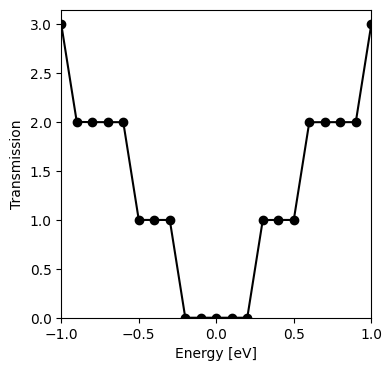

In [57]:
fig, ax = plt.subplots(figsize=(4, 4))
ax.plot(En,Tavg,c="k",marker='o')
ax.set_xlabel("Energy [eV]")
ax.set_ylabel("Transmission")
plt.xlim(-1,1)
plt.ylim(0,None)

For an ideal ballistic conductor, the transmission at each fixed $k_x$ equals the number of propagating channels:

$$
T(E,k_x)=N_{\mathrm{channels}}(E,k_x).
$$


### Visualizing the bond current

Physically:
$$\boldsymbol A_{L,R}(E) $$ describes the spectral weight in the device associated with electronic states injected from the left/right electrode.

For an orthogonal tight-binding Hamiltonian, the bond-resolved spectral transmission from orbital \(i\) to orbital \(j\) can be written, with the convention used below, as
$$
\boldsymbol J_{i\rightarrow j}^{({L,R})}(E,k_x)
=-2\,\operatorname{Im}
\left[
\boldsymbol (H_{ij}(k_x)-E \boldsymbol S_{ij}(k_x))A_{ji}^{({L,R)}}(E,k_x)
\right].$$


In [80]:
E0 = 0.25       # Energy
ik = 0         # Selected transverse k-point
eta = 0.0001
k = bz.k[ik]

In [81]:
Hk = H_device.Hk(k=k, format="array")
Sk = H_device.Sk(k=k, format="array")

# self energies
Sigma_B = SE_bottom.self_energy(E0, k=k)
Sigma_T = SE_top.self_energy(E0, k=k)

z = E0 + 1j * eta
A = z * Sk - Hk

# Greens function
A[np.ix_(idx_bottom, idx_bottom)] -= Sigma_B
A[np.ix_(idx_top,idx_top )] -= Sigma_T

G = np.linalg.inv(A)

# Bottom spectral function
Gamma_B = 1j * (Sigma_B - Sigma_B.conj().T)

Gamma = np.zeros_like(A)
Gamma[np.ix_(idx_bottom, idx_bottom)] = Gamma_B

A_left = G @ Gamma @ G.conj().T

In [82]:
xyz = H_device.geometry.xyz

# Nearest-neighbor bonds
tree = cKDTree(xyz)

bonds = np.array(sorted(tree.query_pairs(r=1.7)),dtype=int).reshape(-1, 2)

atom_i = bonds[:, 0]
atom_j = bonds[:, 1]

#  spectral current from i to j
Jij = -2 * np.imag((Hk[atom_i, atom_j]-z*Sk[atom_i, atom_j]) *A_left[atom_j, atom_i])
threshold = 0.00001 * np.max(np.abs(Jij))
mask = np.abs(Jij) > threshold

i = atom_i[mask]
j = atom_j[mask]
J = Jij[mask]

# Reverse arrows for negative currents
start = np.where(J[:, None] >= 0, xyz[i], xyz[j])
end   = np.where(J[:, None] >= 0, xyz[j], xyz[i])

dx = end[:, 0] - start[:, 0]
dy = end[:, 1] - start[:, 1]

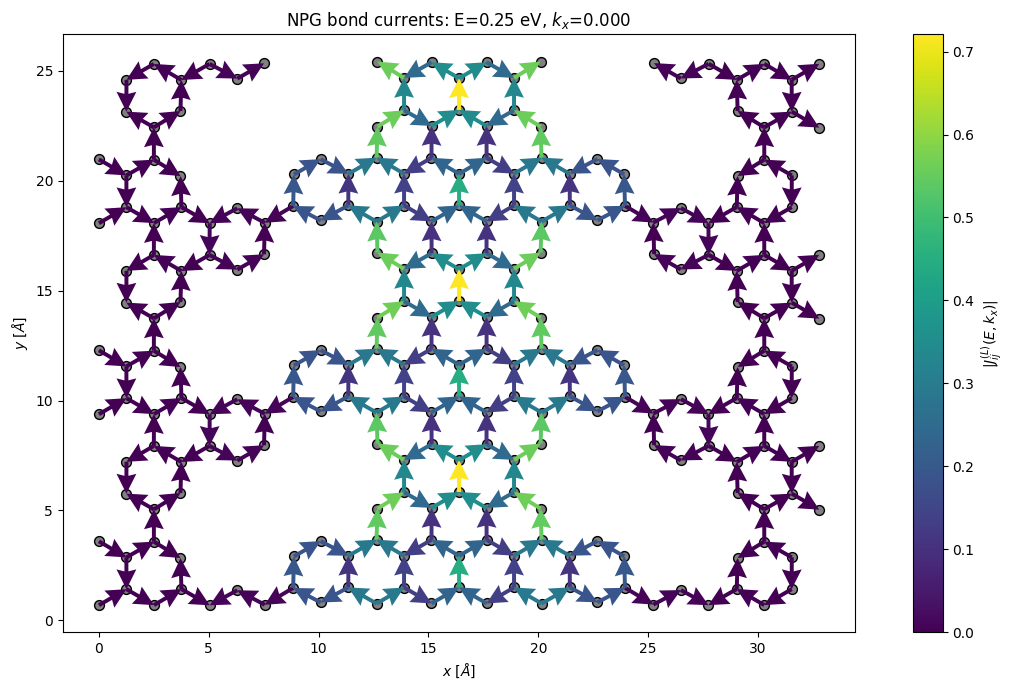

In [83]:
fig, ax = plt.subplots(figsize=(12, 7))
ax.set_aspect("equal")

# Carbon atoms
ax.scatter(xyz[:, 0], xyz[:, 1],s=50, c="gray",zorder=0,edgecolors='k')

# Bond-current arrows
q = ax.quiver(
    start[:, 0],
    start[:, 1],
    dx,
    dy,
    np.abs(J),
    cmap="viridis",
    norm=Normalize(
        vmin=0,
        vmax=np.max(np.abs(Jij))
    ),
    angles="xy",
    scale_units="xy",
    scale=1,
    width=0.005,
    headwidth=5,
    zorder=2
)

fig.colorbar( q, ax=ax,label=r"$|J_{ij}^{(L)}(E,k_x)|$")

ax.set_xlabel(r"$x$ [$\AA$]")
ax.set_ylabel(r"$y$ [$\AA$]")

ax.set_title( rf"NPG bond currents: E={E0:.2f} eV, "rf"$k_x$={k[0]:.3f}")

plt.tight_layout()
plt.show()

## 5. Exercise: How to improve the prunning

The $p_z$-only model is intentionally minimal. Compare it with the full DFT bands and identify the energy range where it works well. Which additional orbitals would you keep if you wanted a better description farther away from the Fermi level?

![title](.//Figures/Orbitals.png)

In [91]:

C_list = (H_dft.atoms.Z == 6).nonzero()[0]
C_atom = H_dft.geometry.atoms[C_list[0]]
Corbs = C_atom.orbitals

# Atoms whose orbitals will be extracted from DFT
C_list = (H_dft.atoms.Z == 6).nonzero()[0]
C_atom = H_dft.geometry.atoms[C_list[0]]
Corbs = C_atom.orbitals

N_list = (H_dft.atoms.Z == 7).nonzero()[0]
N_atom = H_dft.geometry.atoms[N_list[0]]
Norbs  = N_atom.orbitals

print('Nitrogen')
print('orbital number orbtial name')
for i,orb in enumerate(N_atom.orbitals):
    print(i,orb.name())

print('Carbon')
print('orbital number orbtial name')
for i,orb in enumerate(C_atom.orbitals):
    print(i,orb.name())

Nitrogen
orbital number orbtial name
0 2sZ1
1 2sZ2
2 2pyZ1
3 2pzZ1
4 2pxZ1
5 2pyZ2
6 2pzZ2
7 2pxZ2
8 3dxyZ1P
9 3dyzZ1P
10 3dz2Z1P
11 3dxzZ1P
12 3dx2-y2Z1P
Carbon
orbital number orbtial name
0 2sZ1
1 2sZ2
2 2pyZ1
3 2pzZ1
4 2pxZ1
5 2pyZ2
6 2pzZ2
7 2pxZ2
8 3dxyZ1P
9 3dyzZ1P
10 3dz2Z1P
11 3dxzZ1P
12 3dx2-y2Z1P


In [107]:
# List of Carbon and Nitrogen
CN_list = np.array(list(C_list)+list(N_list))
H_tb = H_dft.sub(CN_list)
H_tb.reduce()
H_tb = H_tb.sub_orbital(range(H_tb.geometry.na),[3,
                                                 #fill here,
                                                ]) 
H_tb.reduce()

In [93]:
tmp = H_dft.eigh()
en_dft = tmp[tmp<0].max()
tmp = H_tb.eigh()
en_tb = tmp[tmp<0].max()
print(en_dft, en_tb)

eshift = en_dft - en_tb
H_tb.shift(eshift)
print("Energy shift: ",eshift)

-0.21051013699283047 -0.16541673947831298
Energy shift:  -0.04509339751451749


In [94]:
nk=30
band_tb = si.BandStructure(H_tb, [[0.5, 0, 0], [0, 0, 0], [0, 0.5, 0]],nk, [r'$X$', r'$\Gamma$', r'$Y$'])
lk, kt, kl = band_tb.lineark(True)
bs_tb =band_tb.apply.array.eigh()

Text(0, 0.5, '$E-E_F$ (eV)')

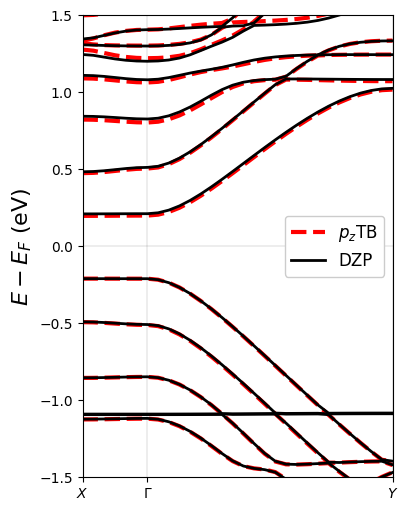

In [98]:
fig = plt.figure('Band comparison',figsize=(4,6))
ax = fig.add_subplot()

firsttime=True
for bk in bs_tb.T:
    bk=bk 
    if(firsttime):
        ax.plot(lk, bk, 'r--', label=r'$p_z$TB',lw=3)
        firsttime=False
    else:
        ax.plot(lk, bk, 'r--',lw=3)


firsttime= True
for bk in bs_dft.T:
    if(firsttime):
        ax.plot(lk, bk, 'k-', label='DZP',lw=2)
        firsttime=False
    else:
        ax.plot(lk, bk, 'k',lw=2)

xcoords = kt
for k in xcoords:
    plt.axvline(x=k,c='k',lw=0.1)  

plt.axhline(y=0,c='k',lw=0.1)  

plt.xticks(kt, kl)        
ax.legend(loc='center right',fontsize=12,framealpha=1)
plt.ylim(-1.5,1.5)
plt.xlim(kt[0],kt[2])
plt.ylabel(r'$E-E_F$ (eV)',fontsize=16)

# II. STO

## 1. Load the Hamiltonian

Read the SrTiO₃ (STO) Hamiltonian from a SIESTA `.HSX` file using `sisl`.

In [117]:
# Path to the SIESTA Hamiltonian file
ham_path = "STO-1uc_SZ_minimal/atoms.HSX"
H = si.get_sile(ham_path).read_hamiltonian()

In [118]:
# Path to the SIESTA Hamiltonian file
ham_path = "STO-1uc_SZ_minimal/atoms.HSX"
H = si.get_sile(ham_path).read_hamiltonian()

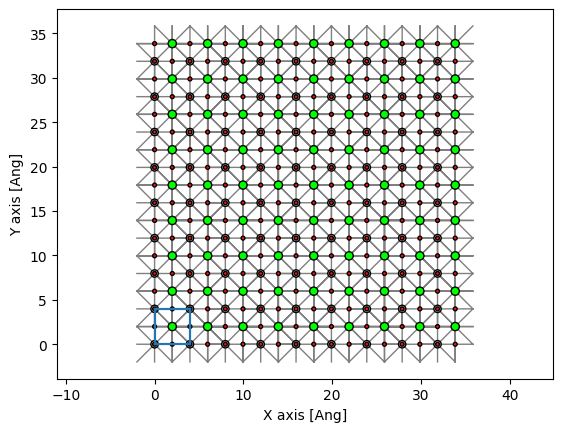

In [126]:
H.geometry.plot(axes='xy',nsc=[9,9,1],backend='matplotlib')

![title](.//Figures/STO.jpg)

## 2. Atom-projected density of states (PDOS)

The atom-projected density of states (PDOS) shows how much each element contributes at a given energy. Use it to identify which atoms are important in the energy range you want to preserve when pruning the Hamiltonian.

In [110]:
# Energy window and sampling parameters
Emin = -5
Emax = 5
nE = 100
sigma = 0.1
nk = 4

kgrid = (nk, nk, nk)
na = H.na  # Number of atoms

# Energies at which the PDOS is evaluated
E = np.linspace(Emin, Emax, nE)

# Gaussian broadening (uses sisl's default width)
distribution = si.get_distribution("gaussian", smearing = sigma)

# Sample the Brillouin zone with a Monkhorst-Pack grid
bz = si.MonkhorstPack(H, kgrid)

# Average the orbital-resolved PDOS over the k-point grid
orbital_PDOS = bz.apply.average.eigenstate(
    wrap=lambda es: es.PDOS(E, distribution=distribution)
)

# Select the total (charge) component
orbital_PDOS = orbital_PDOS[0]

# Accumulate PDOS by chemical element
atom_PDOS = {
    'O': np.zeros(nE),
    'Ti': np.zeros(nE),
    'Sr': np.zeros(nE),
}

for ia in range(na):
    species = H.atoms[ia].symbol
    orbitals = H.a2o(ia, all=True)  # Global orbital indices for this atom
    atom_PDOS[species] += orbital_PDOS[orbitals].sum(axis=0)

# Sum the element-resolved contributions to obtain the total DOS
total_DOS = np.sum(list(atom_PDOS.values()), axis=0)

Text(0, 0.5, 'DOS (states/eV)')

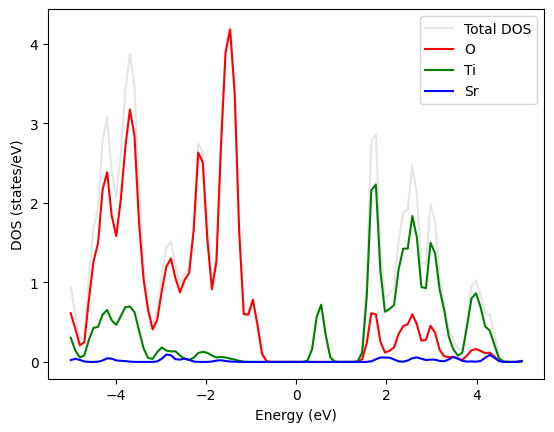

In [111]:
# Compare the total DOS with the contributions from each element
fig, ax = plt.subplots()
ax.plot(E, total_DOS, 'k', alpha=0.1, label='Total DOS')

colors = 'rgb'
for i, species in enumerate(atom_PDOS):
    ax.plot(E, atom_PDOS[species], label=species, color=colors[i])

ax.legend()
ax.set_xlabel('Energy (eV)')
ax.set_ylabel('DOS (states/eV)')

## 3. Fatband plot

A fatband plot displays the band structure with colored weights that indicate how strongly selected orbitals contribute to each band. Larger weights appear as thicker colored regions.

Choose which orbital groups to display below. Any orbitals not selected are combined into a **rest** group.

In [112]:
# Orbital indices are local to each species' basis (see orbital_clusters below).
# Uncomment groups to compare their contributions in the fatband plot.
orbital_clusters_to_plot = {
    'Ti': {
        # '4s': [0],
        't_2g': [1, 2, 4],
        # 'e_g': [3, 5],
    },
    'O': {
        '2s': [0],
        # '2p': [1, 2, 3],
    },
    'Sr': {
        '5s': [0],
    },
}

![title](.//Figures/octahedral.png)

In [113]:
palette = plt.get_cmap("tab10")
groups_dict = {}
rest_orbitals = []

# Convert species-local orbital selections to global Hamiltonian indices
for ia, atom in enumerate(H.atoms):
    species = atom.symbol
    global_indices = H.geometry.a2o(ia, all=True)
    selected = set()

    for orb_type, indices in orbital_clusters_to_plot.get(species, {}).items():
        key = (species, orb_type)
        if key not in groups_dict:
            groups_dict[key] = []

        groups_dict[key].extend(int(global_indices[i]) for i in indices)
        selected.update(indices)

    # Collect all orbitals not assigned to a named group
    rest_orbitals.extend(
        int(global_indices[i])
        for i in range(len(global_indices))
        if i not in selected
    )

# Assign a color to each selected orbital group
groups = [
    {
        "name": rf"{species} ${orb_type}$",
        "orbitals": indices,
        "color": to_hex(palette(i % 10)),
    }
    for i, ((species, orb_type), indices) in enumerate(groups_dict.items())
]

# Show unselected orbitals in gray
if rest_orbitals:
    groups.append({"name": "rest","orbitals": rest_orbitals,"color": "#808080", })

#k-point sampling of band structure
nk = 100 
# Define the high-symmetry k-point path: Γ–X–M–Γ
band = si.BandStructure(H,[[0, 0, 0], [0.5, 0, 0], [0.5, 0.5, 0], [0, 0, 0]],    nk, ["Γ", "X", "M", "Γ"],)


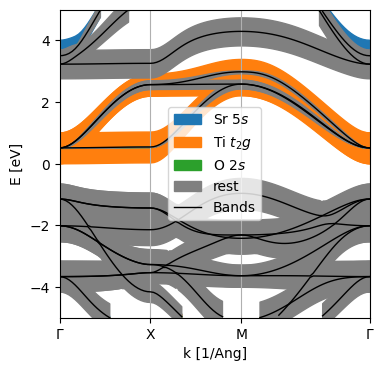

In [20]:
# Plot orbital weights on the original band structure
fatbands = band.plot.fatbands( groups=groups,  Erange=(-5, 5),  E0=0,  fatbands_scale=1,  backend="matplotlib",)

fig = fatbands.get().figure
ax = fatbands.get().axes
fig.set_figwidth(4)
fig.set_figheight(4)
ax.legend()

## 4. Prune the Hamiltonian

Use the PDOS and fatband plots to decide which orbitals to **keep**. Comment out orbital groups in the lists below to remove them from the pruned Hamiltonian.

**Exercise:** Try keeping the orbitals most relevant to the valence bands, conduction bands, or bands near the gap. Compare the resulting band structures with the original.

In [114]:
# Only the orbital groups listed here are retained for each element.
# Comment out a line to exclude that group during pruning.
O_prune_orbitals = [ '2s',  '2p',]

Ti_prune_orbitals = [   '4s',   't_2g',   'e_g']

Sr_prune_orbitals = [   '5s',]

### Apply the orbital selection

Translate each selected orbital group into basis-function indices, then create a copy of the Hamiltonian containing only those orbitals. If no orbitals are selected for an element, its atoms are removed.

In [115]:
# Orbital indices within the basis of each element
orbital_clusters = {
    'Ti': {'4s': [0], 't_2g': [1, 2, 4], 'e_g': [3, 5]},
    'O': {'2s': [0], '2p': [1, 2, 3]},
    'Sr': {'5s': [0]},
}

# Expand the selected group names into local orbital indices
prune_orbitals = {
    'O': sum([orbital_clusters['O'][v] for v in O_prune_orbitals], []),
    'Ti': sum([orbital_clusters['Ti'][v] for v in Ti_prune_orbitals], []),
    'Sr': sum([orbital_clusters['Sr'][v] for v in Sr_prune_orbitals], []),
}

# Work on a copy so the original Hamiltonian remains available for comparison
Hsub = H.copy()
for species, indices in prune_orbitals.items():
    atom_indices = [i for i, atom in enumerate(Hsub.atoms) if atom.symbol == species]

    if indices:
        # Retain only the chosen orbitals on atoms of this element
        Hsub = Hsub.sub_orbital(atom_indices, indices)
    else:
        # Remove atoms of this element if none of their orbitals are kept
        Hsub = Hsub.remove(atom_indices)

# Reduce redundant sparse-matrix entries
Hsub.reduce()

## 5. Compare the band structures

Plot the original and pruned band structures along the same k-point path. Check which bands are preserved and where the pruning changes their energies.

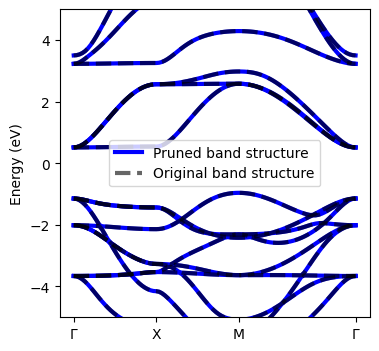

In [116]:
# Eigenvalues of the original Hamiltonian along the selected k-point path
original_bands = band.apply.array.eigh()
k = band.lineark()
ticks, labels = band.lineartick()

# Use the same path and sampling for the pruned Hamiltonian
pruned_band = si.BandStructure(
    Hsub,
    [[0, 0, 0],
     [0.5, 0, 0],
     [0.5, 0.5, 0],
     [0, 0, 0]],
    nk,
    ["Γ", "X", "M", "Γ"],
)
pruned_bands = pruned_band.apply.array.eigh()

fig, ax = plt.subplots()
fig.set_figwidth(4)
fig.set_figheight(4)


# Solid blue lines: pruned bands
for i, energies in enumerate(pruned_bands.T):
    ax.plot(k, energies, 'b',
            label='Pruned band structure' if i == 0 else None,lw = 3)

# Dashed black lines: original bands
for i, energies in enumerate(original_bands.T):
    ax.plot(k, energies, 'k--', alpha=0.6, lw = 3,
            label='Original band structure' if i == 0 else None)

ax.set_ylim(-5, 5)
ax.set_xticks(ticks)
ax.set_xticklabels(labels)
ax.set_ylabel('Energy (eV)')
ax.legend()